<a href="https://colab.research.google.com/github/samritha07/Deep-Learning/blob/main/DL_EXP_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# PART A: DATASET PREPARATION

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from sklearn.model_selection import train_test_split

STUDENT_NAME = "SAMRITHA S"
ROLL_NO = "24BAD103"
print(f"Student: {STUDENT_NAME} | Roll No: {ROLL_NO}")
print("TensorFlow/Keras version:", keras.__version__)

Student: SAMRITHA S | Roll No: 24BAD103
TensorFlow/Keras version: 3.13.2


In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()
print(f"[{ROLL_NO}] MNIST loaded successfully")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[24BAD103] MNIST loaded successfully


[24BAD103] Training set : (60000, 28, 28), labels: (60000,)
[24BAD103] Test set     : (10000, 28, 28), labels: (10000,)
[24BAD103] Classes      : [0 1 2 3 4 5 6 7 8 9]
[24BAD103] Class counts (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


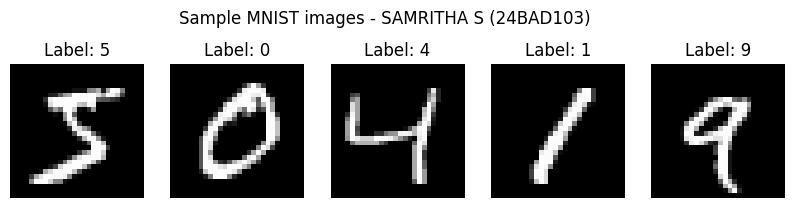

In [3]:
print(f"[{ROLL_NO}] Training set : {x_train_full.shape}, labels: {y_train_full.shape}")
print(f"[{ROLL_NO}] Test set     : {x_test.shape}, labels: {y_test.shape}")
print(f"[{ROLL_NO}] Classes      : {np.unique(y_train_full)}")
print(f"[{ROLL_NO}] Class counts (train): {np.bincount(y_train_full)}")

fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(x_train_full[i], cmap="gray")
    ax.set_title(f"Label: {y_train_full[i]}")
    ax.axis("off")
plt.suptitle(f"Sample MNIST images - {STUDENT_NAME} ({ROLL_NO})")
plt.show()

In [4]:
print(f"[{ROLL_NO}] Single image shape : {x_train_full[0].shape}")
print(f"[{ROLL_NO}] Data type          : {x_train_full.dtype}")
print(f"[{ROLL_NO}] Pixel range        : {x_train_full.min()} to {x_train_full.max()}")
print(f"[{ROLL_NO}] Flattened size     : {28*28} features per image")

[24BAD103] Single image shape : (28, 28)
[24BAD103] Data type          : uint8
[24BAD103] Pixel range        : 0 to 255
[24BAD103] Flattened size     : 784 features per image


In [5]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print(f"[{ROLL_NO}] After normalization -> dtype: {x_train_full.dtype}, "
      f"min: {x_train_full.min()}, max: {x_train_full.max()}")

[24BAD103] After normalization -> dtype: float32, min: 0.0, max: 1.0


In [6]:
x_train_full = x_train_full.reshape(len(x_train_full), 28 * 28)
x_test = x_test.reshape(len(x_test), 28 * 28)
print(f"[{ROLL_NO}] Reshaped train: {x_train_full.shape}, test: {x_test.shape}")

[24BAD103] Reshaped train: (60000, 784), test: (10000, 784)


In [7]:
# MNIST already provides a 60,000/10,000 train/test split.
# A further 10% of the training data is held out for validation.
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.1, random_state=42)

print(f"[{ROLL_NO}] Training samples  : {x_train.shape[0]}")
print(f"[{ROLL_NO}] Validation samples: {x_val.shape[0]}")
print(f"[{ROLL_NO}] Testing samples   : {x_test.shape[0]}")

[24BAD103] Training samples  : 54000
[24BAD103] Validation samples: 6000
[24BAD103] Testing samples   : 10000


In [8]:
# In an autoencoder the target is the input itself (unsupervised reconstruction).
y_train_ae, y_val_ae, y_test_ae = x_train, x_val, x_test
print(f"[{ROLL_NO}] Input shape: {x_train.shape} | Target shape: {y_train_ae.shape}")
print(f"[{ROLL_NO}] Target is identical to input: {np.array_equal(x_train, y_train_ae)}")

[24BAD103] Input shape: (54000, 784) | Target shape: (54000, 784)
[24BAD103] Target is identical to input: True


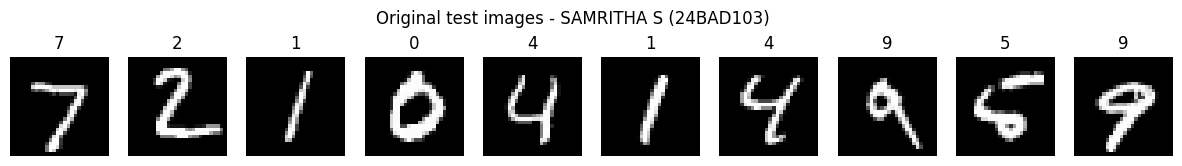

In [9]:
n = 10
plt.figure(figsize=(15, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"{y_test[i]}")
    plt.axis("off")
plt.suptitle(f"Original test images - {STUDENT_NAME} ({ROLL_NO})")
plt.show()

---
# PART B: IMPLEMENTING THE AUTOENCODER MODEL

In [10]:
input_dim = x_train.shape[1]      # 784
latent_dim = 32                   # bottleneck size
input_img = Input(shape=(input_dim,), name="input_layer")
print(f"[{ROLL_NO}] Input dimension: {input_dim}, Latent dimension: {latent_dim}")

[24BAD103] Input dimension: 784, Latent dimension: 32


In [11]:
x = layers.Dense(128, activation="relu", name="encoder_dense_1")(input_img)
x = layers.Dense(64, activation="relu", name="encoder_dense_2")(x)
print(f"[{ROLL_NO}] Encoder hidden layers created: 784 -> 128 -> 64")

[24BAD103] Encoder hidden layers created: 784 -> 128 -> 64


In [12]:
bottleneck = layers.Dense(latent_dim, activation="relu", name="bottleneck")(x)
print(f"[{ROLL_NO}] Bottleneck: {latent_dim} neurons vs input {input_dim} "
      f"(compression ratio {input_dim/latent_dim:.1f}x)")

[24BAD103] Bottleneck: 32 neurons vs input 784 (compression ratio 24.5x)


In [13]:
dec_1 = layers.Dense(64, activation="relu", name="decoder_dense_1")
dec_2 = layers.Dense(128, activation="relu", name="decoder_dense_2")
dec_out = layers.Dense(input_dim, activation="sigmoid", name="output_layer")  # sigmoid for 0-1 pixels

reconstructed = dec_out(dec_2(dec_1(bottleneck)))
print(f"[{ROLL_NO}] Decoder layers created: 32 -> 64 -> 128 -> 784 (ReLU hidden, Sigmoid output)")

[24BAD103] Decoder layers created: 32 -> 64 -> 128 -> 784 (ReLU hidden, Sigmoid output)


In [14]:
autoencoder = Model(input_img, reconstructed, name="autoencoder")
encoder = Model(input_img, bottleneck, name="encoder")

# Standalone decoder that reuses the trained decoder layers (needed in Part D)
latent_input = Input(shape=(latent_dim,), name="latent_input")
decoder = Model(latent_input, dec_out(dec_2(dec_1(latent_input))), name="decoder")
print(f"[{ROLL_NO}] Autoencoder, Encoder and Decoder models built")

[24BAD103] Autoencoder, Encoder and Decoder models built


In [15]:
autoencoder.compile(optimizer="adam", loss="mse")
print(f"[{ROLL_NO}] Model compiled with Adam optimizer and Mean Squared Error loss")

[24BAD103] Model compiled with Adam optimizer and Mean Squared Error loss


In [16]:
print(f"Model summary - {STUDENT_NAME} ({ROLL_NO})")
autoencoder.summary()

Model summary - SAMRITHA S (24BAD103)


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
try:
    keras.utils.plot_model(autoencoder, show_shapes=True, show_layer_names=True)
except Exception as e:
    print("plot_model needs pydot/graphviz; skipping diagram:", e)

---
# PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

In [18]:
history = autoencoder.fit(
    x_train, y_train_ae,
    epochs=30,
    batch_size=256,
    shuffle=True,
    validation_data=(x_val, y_val_ae),
    verbose=1
)
print(f"[{ROLL_NO}] Training completed")

Epoch 1/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0646 - val_loss: 0.0379
Epoch 2/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0311 - val_loss: 0.0267
Epoch 3/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0244 - val_loss: 0.0222
Epoch 4/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - loss: 0.0206 - val_loss: 0.0193
Epoch 5/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0182 - val_loss: 0.0173
Epoch 6/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0166 - val_loss: 0.0161
Epoch 7/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.0156 - val_loss: 0.0154
Epoch 8/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0148 - val_loss: 0.0145
Epoch 9/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0141 - val_loss: 0.0138
Epoch 10/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0134 - val_loss: 0.0132
Epoch 11/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0129 - val_loss: 0.0127
Epoch 12/30
211/211 ━━━━━━━━━━━━━━━━━━━━ 

In [19]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
print(f"[{ROLL_NO}] Final training loss  : {train_loss[-1]:.6f}")
print(f"[{ROLL_NO}] Final validation loss: {val_loss[-1]:.6f}")
print(f"[{ROLL_NO}] Best validation loss : {min(val_loss):.6f} (epoch {int(np.argmin(val_loss))+1})")

[24BAD103] Final training loss  : 0.008954
[24BAD103] Final validation loss: 0.009272
[24BAD103] Best validation loss : 0.009217 (epoch 29)


In [20]:
test_loss = autoencoder.evaluate(x_test, y_test_ae, verbose=0)
print(f"[{ROLL_NO}] Test loss (MSE): {test_loss:.6f}")

[24BAD103] Test loss (MSE): 0.008900


In [21]:
x_test_recon = autoencoder.predict(x_test, verbose=0)
mse_per_image = np.mean((x_test - x_test_recon) ** 2, axis=1)
print(f"[{ROLL_NO}] Overall reconstruction MSE : {mse_per_image.mean():.6f}")
print(f"[{ROLL_NO}] Min / Max per-image MSE    : {mse_per_image.min():.6f} / {mse_per_image.max():.6f}")

[24BAD103] Overall reconstruction MSE : 0.008900
[24BAD103] Min / Max per-image MSE    : 0.000622 / 0.043461


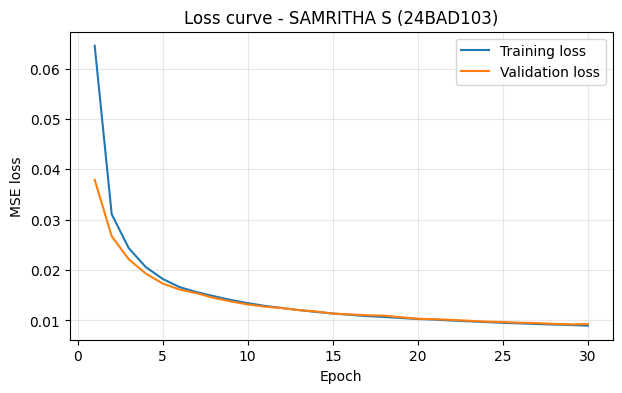

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_loss) + 1), train_loss, label="Training loss")
plt.plot(range(1, len(val_loss) + 1), val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title(f"Loss curve - {STUDENT_NAME} ({ROLL_NO})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

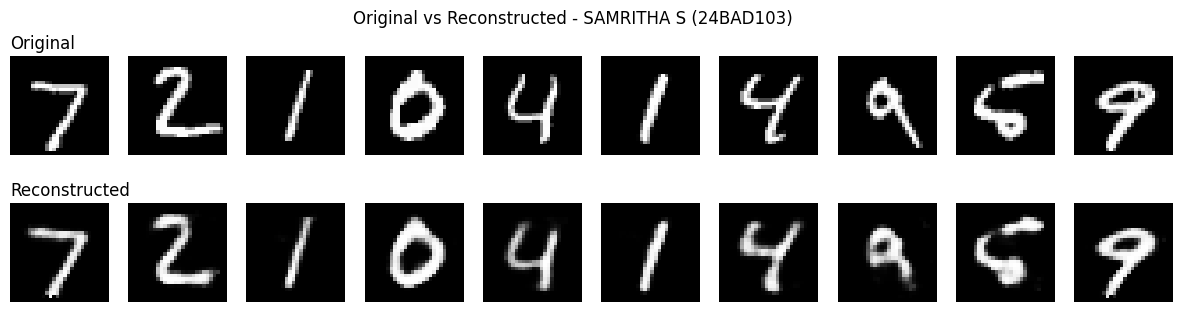

In [23]:
n = 10
plt.figure(figsize=(15, 3.5))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    if i == 0: ax.set_title("Original", loc="left")
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(x_test_recon[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    if i == 0: ax.set_title("Reconstructed", loc="left")
plt.suptitle(f"Original vs Reconstructed - {STUDENT_NAME} ({ROLL_NO})")
plt.show()

---
# PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT

In [24]:
x_test_latent = encoder.predict(x_test, verbose=0)
print(f"[{ROLL_NO}] Latent representation extracted")
print(f"[{ROLL_NO}] First test sample latent vector:\n", np.round(x_test_latent[0], 3))

[24BAD103] Latent representation extracted
[24BAD103] First test sample latent vector:
 [7.6400e+00 0.0000e+00 0.0000e+00 1.0232e+01 9.9150e+00 5.3110e+00
 1.1111e+01 2.0028e+01 1.3429e+01 1.6076e+01 4.7400e+00 1.1572e+01
 6.4830e+00 4.5860e+00 6.0740e+00 1.2956e+01 1.4124e+01 1.5000e+01
 1.4731e+01 3.4890e+00 1.5952e+01 1.2000e-02 4.1430e+00 1.4581e+01
 8.5810e+00 1.1955e+01 1.2439e+01 1.0581e+01 0.0000e+00 1.6661e+01
 7.8850e+00 4.9330e+00]


In [25]:
print(f"[{ROLL_NO}] Original data shape  : {x_test.shape}")
print(f"[{ROLL_NO}] Compressed data shape: {x_test_latent.shape}")
print(f"[{ROLL_NO}] Dimensions reduced from {x_test.shape[1]} to {x_test_latent.shape[1]} "
      f"({100*(1 - x_test_latent.shape[1]/x_test.shape[1]):.1f}% reduction, "
      f"{x_test.shape[1]/x_test_latent.shape[1]:.1f}x compression)")

[24BAD103] Original data shape  : (10000, 784)
[24BAD103] Compressed data shape: (10000, 32)
[24BAD103] Dimensions reduced from 784 to 32 (95.9% reduction, 24.5x compression)


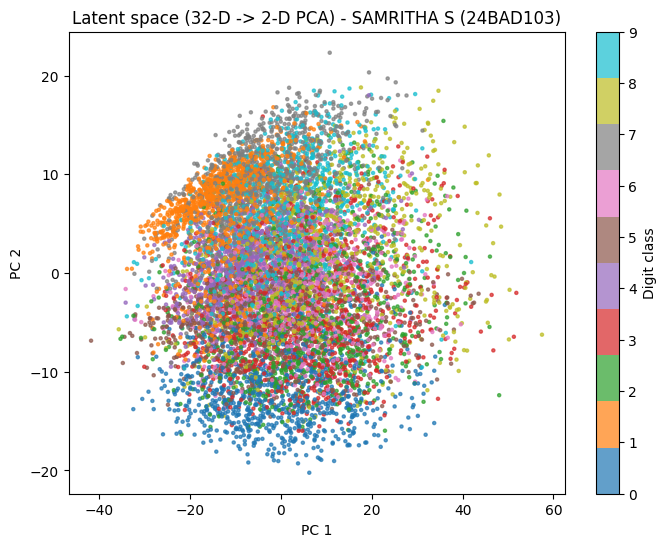

In [26]:
# The 32-D latent space is projected to 2-D with PCA for plotting
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(x_test_latent)

plt.figure(figsize=(8, 6))
sc = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=y_test, cmap="tab10", s=5, alpha=0.7)
plt.colorbar(sc, label="Digit class")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title(f"Latent space (32-D -> 2-D PCA) - {STUDENT_NAME} ({ROLL_NO})")
plt.show()

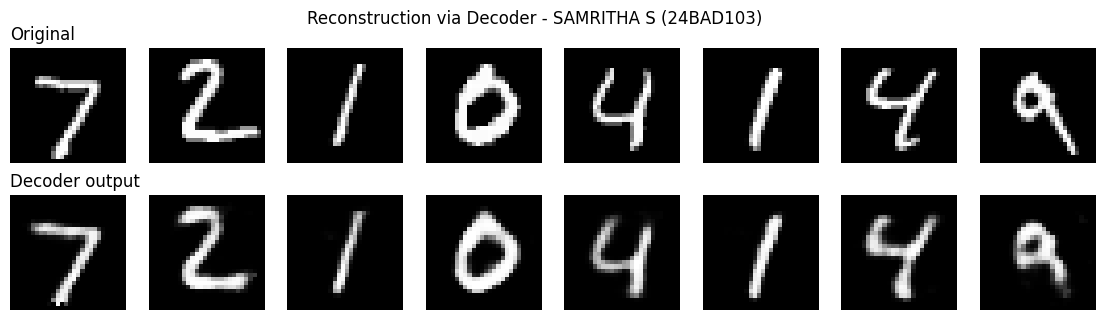

[24BAD103] MSE on selected samples: 0.008431


In [27]:
idx = [0, 1, 2, 3, 4, 5, 6, 7]                       # selected test samples
decoded_imgs = decoder.predict(x_test_latent[idx], verbose=0)

n = len(idx)
plt.figure(figsize=(14, 3.5))
for i, k in enumerate(idx):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[k].reshape(28, 28), cmap="gray"); ax.axis("off")
    if i == 0: ax.set_title("Original", loc="left")
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray"); ax.axis("off")
    if i == 0: ax.set_title("Decoder output", loc="left")
plt.suptitle(f"Reconstruction via Decoder - {STUDENT_NAME} ({ROLL_NO})")
plt.show()
print(f"[{ROLL_NO}] MSE on selected samples: {np.mean((x_test[idx]-decoded_imgs)**2):.6f}")